In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

F = np.loadtxt("f_linear_triangulation_lp.csv", delimiter=",")
print(F.shape)   # (1848, 20)

(1848, 20)


In [2]:
tree = {0: [1, 10, 11, 12, 2, 3, 4, 5, 6], 1: [8, 9], 2: [13], 3: [14, 15],
        4: [7], 7: [16, 17, 18], 18: [19]}

U = F.copy()
for parent, children in tree.items():
    U[:, parent] -= F[:, children].sum(axis=1)

In [3]:
rows, cols = np.mgrid[0:44, 0:46]          # 42x44 grid plus a zero border
T = mtri.Triangulation(cols.ravel(), rows.ravel())

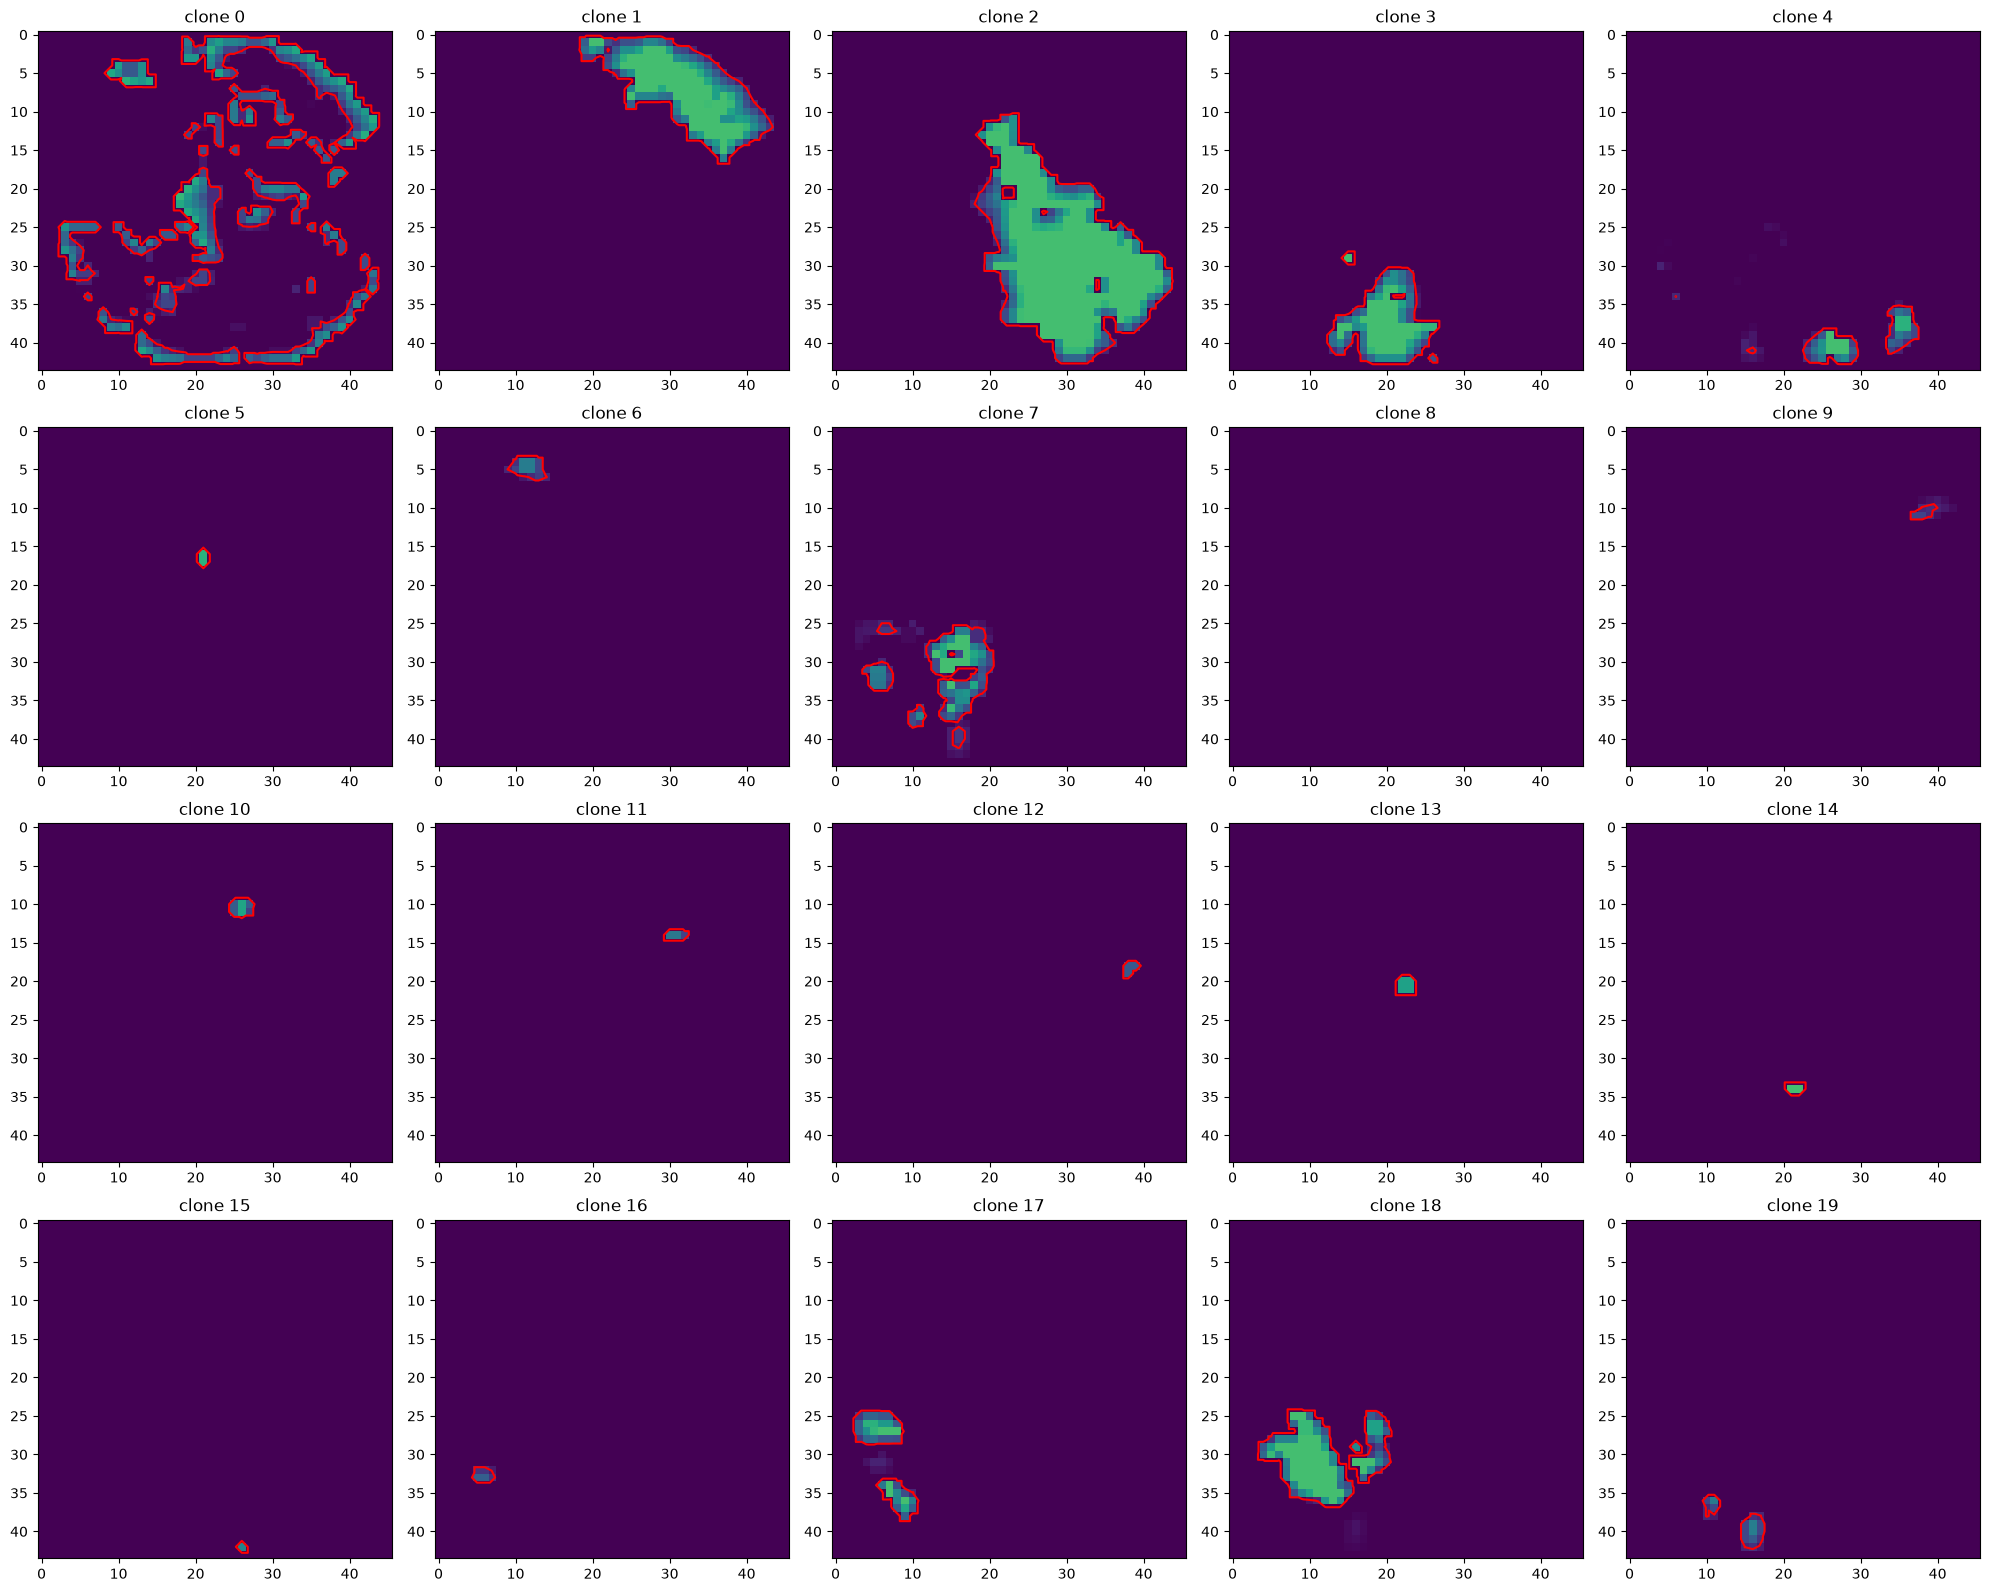

In [4]:
tau = 0.1
boundaries = {}
fig, axes = plt.subplots(4, 5, figsize=(20, 16))

for k, ax in enumerate(axes.ravel()):
    grid = np.pad(U[:, k].reshape(42, 44), 1)
    ax.imshow(grid, cmap="viridis", vmin=0, vmax=1)
    if grid.max() >= tau:
        cs = ax.tricontour(T, grid.ravel(), levels=[tau], colors="red")
        boundaries[k] = [seg.tolist() for seg in cs.allsegs[0]]
    ax.set_title(f"clone {k}")

plt.tight_layout()
plt.savefig("boundaries_linear_triangulation.png", dpi=120)

In [5]:
import json
with open("boundaries_linear_triangulation.json", "w") as fh:
    json.dump(boundaries, fh)

In [6]:
print("F max:", np.round(F.max(axis=0), 2))
print("U max:", np.round(U.max(axis=0), 2))

F max: [0.7  0.7  0.7  0.7  0.7  0.64 0.42 0.7  0.   0.2  0.58 0.39 0.28 0.57
 0.7  0.45 0.3  0.7  0.7  0.43]
U max: [0.67 0.7  0.7  0.7  0.7  0.64 0.42 0.7  0.   0.2  0.58 0.39 0.28 0.57
 0.7  0.45 0.3  0.7  0.7  0.43]


In [7]:
print(len(boundaries), sorted(boundaries.keys()))

19 [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
